In [60]:
import pandas as pd #Pandas is used to read and manipulate datasets in tabular format.
import numpy as np #NumPy is used for numerical calculations and array operations.
import seaborn as sns #Seaborn helps us create statistical visualizations.
import matplotlib.pyplot as plt #Matplotlib is used to create graphs and charts.

from sklearn.model_selection import train_test_split, GridSearchCV #Divides our dataset into training and testing data.
from sklearn.preprocessing import StandardScaler #Standardizes feature values so they are on comparable scales.

from sklearn.linear_model import LogisticRegression #Imports the classification algorithm we need.

from sklearn.pipeline import Pipeline #Combines preprocessing and model training into one workflow.

from sklearn.metrics import (
    accuracy_score, #Calculates the percentage of correct predictions.
    precision_score, #Measures how many predicted resignations were actually resignations.
    recall_score, #Measures how many actual resignations the model successfully detected.
    f1_score, #Combines precision and recall into one metric.
    confusion_matrix, #Shows correct and incorrect predictions.
    classification_report, #Provides precision, recall, F1-score and support.
    roc_auc_score #Measures how well the model distinguishes between the two classes.
)

In [61]:
employee_data = pd.read_csv("employee_turnover.csv")

In [62]:
employee_data.info()
employee_data

<class 'pandas.DataFrame'>
RangeIndex: 1350 entries, 0 to 1349
Data columns (total 16 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Job_Satisfaction                         1350 non-null   float64
 1   Performance_Rating                       1350 non-null   float64
 2   Years_At_Company                         1350 non-null   float64
 3   Work_Life_Balance                        1350 non-null   float64
 4   Distance_From_Home                       1350 non-null   float64
 5   Monthly_Income                           1350 non-null   float64
 6   Education_Level                          1350 non-null   float64
 7   Age                                      1350 non-null   float64
 8   Num_Companies_Worked                     1350 non-null   float64
 9   Employee_Role                            1350 non-null   float64
 10  Annual_Bonus                             1350 non-null   fl

,Job_Satisfaction,Performance_Rating,Years_At_Company,Work_Life_Balance,Distance_From_Home,Monthly_Income,Education_Level,Age,Num_Companies_Worked,Employee_Role,Annual_Bonus,Training_Hours,Department,Annual_Bonus_Squared,Annual_Bonus_Training_Hours_Interaction,Employee_Turnover
0,0.562326,0.141129,0.123989,0.347583,0.330353,0.328853,0.600933,0.315990,0.768736,0.090671,0.324786,0.669193,0.602932,0.105486,0.217344,0
1,0.017041,0.559047,0.511203,0.793908,0.423550,0.553450,0.742009,0.897146,0.380035,0.601633,0.694611,0.043271,0.800761,0.482484,0.030056,0
2,0.774699,0.604371,0.798174,0.260500,0.804034,0.131800,0.775178,0.830947,0.218726,0.972936,0.153476,0.701336,0.705275,0.023555,0.107638,1
3,0.628174,0.385249,0.230104,0.516809,0.272248,0.589249,0.482409,0.090507,0.402746,0.132842,0.305973,0.549688,0.600531,0.093620,0.168190,0
4,0.799183,0.199967,0.839029,0.247927,0.341934,0.076818,0.055356,0.680860,0.923341,0.493017,0.844094,0.793751,0.664679,0.712494,0.670000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1345,0.914733,0.965914,0.147215,0.686677,0.251346,0.572003,0.089679,0.127247,0.125553,0.346950,0.450783,0.754675,0.905320,0.203205,0.340194,1
1346,0.396906,0.182952,0.877941,0.824077,0.774960,0.057290,0.556719,0.235014,0.119685,0.781613,0.211581,0.500812,0.526096,0.044767,0.105962,1
1347,0.099171,0.363498,0.849120,0.462270,0.763922,0.585370,0.975760,0.557090,0.782690,0.384706,0.449095,0.270280,0.253656,0.201686,0.121381,1
1348,0.048193,0.453892,0.640611,0.335230,0.952724,0.638797,0.993664,0.801292,0.510281,0.164325,0.649934,0.151225,0.405705,0.422414,0.098286,1


In [63]:
employee_data.shape

(1350, 16)

In [64]:
employee_data.isnull().sum()

Job_Satisfaction                           0
Performance_Rating                         0
Years_At_Company                           0
Work_Life_Balance                          0
Distance_From_Home                         0
Monthly_Income                             0
Education_Level                            0
Age                                        0
Num_Companies_Worked                       0
Employee_Role                              0
Annual_Bonus                               0
Training_Hours                             0
Department                                 0
Annual_Bonus_Squared                       0
Annual_Bonus_Training_Hours_Interaction    0
Employee_Turnover                          0
dtype: int64

In [65]:
employee_data = employee_data.drop_duplicates()

In [66]:
employee_data

,Job_Satisfaction,Performance_Rating,Years_At_Company,Work_Life_Balance,Distance_From_Home,Monthly_Income,Education_Level,Age,Num_Companies_Worked,Employee_Role,Annual_Bonus,Training_Hours,Department,Annual_Bonus_Squared,Annual_Bonus_Training_Hours_Interaction,Employee_Turnover
0,0.562326,0.141129,0.123989,0.347583,0.330353,0.328853,0.600933,0.315990,0.768736,0.090671,0.324786,0.669193,0.602932,0.105486,0.217344,0
1,0.017041,0.559047,0.511203,0.793908,0.423550,0.553450,0.742009,0.897146,0.380035,0.601633,0.694611,0.043271,0.800761,0.482484,0.030056,0
2,0.774699,0.604371,0.798174,0.260500,0.804034,0.131800,0.775178,0.830947,0.218726,0.972936,0.153476,0.701336,0.705275,0.023555,0.107638,1
3,0.628174,0.385249,0.230104,0.516809,0.272248,0.589249,0.482409,0.090507,0.402746,0.132842,0.305973,0.549688,0.600531,0.093620,0.168190,0
4,0.799183,0.199967,0.839029,0.247927,0.341934,0.076818,0.055356,0.680860,0.923341,0.493017,0.844094,0.793751,0.664679,0.712494,0.670000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1343,0.913396,0.372480,0.724462,0.615364,0.038462,0.460149,0.672546,0.309867,0.736024,0.934873,0.270449,0.587684,0.013996,0.073142,0.158938,0
1344,0.666407,0.438163,0.814235,0.323908,0.298281,0.872767,0.472606,0.106409,0.012070,0.738512,0.662816,0.782517,0.004943,0.439326,0.518665,0
1345,0.914733,0.965914,0.147215,0.686677,0.251346,0.572003,0.089679,0.127247,0.125553,0.346950,0.450783,0.754675,0.905320,0.203205,0.340194,1
1347,0.099171,0.363498,0.849120,0.462270,0.763922,0.585370,0.975760,0.557090,0.782690,0.384706,0.449095,0.270280,0.253656,0.201686,0.121381,1


In [67]:
employee_data.info()

<class 'pandas.DataFrame'>
Index: 900 entries, 0 to 1348
Data columns (total 16 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Job_Satisfaction                         900 non-null    float64
 1   Performance_Rating                       900 non-null    float64
 2   Years_At_Company                         900 non-null    float64
 3   Work_Life_Balance                        900 non-null    float64
 4   Distance_From_Home                       900 non-null    float64
 5   Monthly_Income                           900 non-null    float64
 6   Education_Level                          900 non-null    float64
 7   Age                                      900 non-null    float64
 8   Num_Companies_Worked                     900 non-null    float64
 9   Employee_Role                            900 non-null    float64
 10  Annual_Bonus                             900 non-null    float64


In [68]:
employee_data["Employee_Turnover"].value_counts()

Employee_Turnover
0    458
1    442
Name: count, dtype: int64

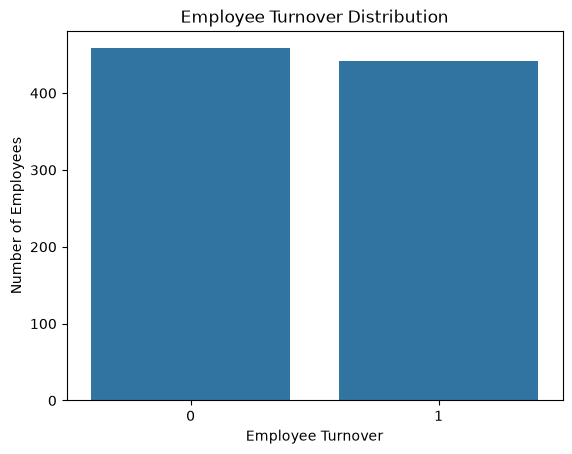

In [69]:
sns.countplot(data=employee_data, x="Employee_Turnover")

plt.title("Employee Turnover Distribution")
plt.xlabel("Employee Turnover")
plt.ylabel("Number of Employees")

plt.show()

In [70]:
X = employee_data.drop(columns=["Employee_Turnover"])
y = employee_data["Employee_Turnover"]

In [71]:
X

,Job_Satisfaction,Performance_Rating,Years_At_Company,Work_Life_Balance,Distance_From_Home,Monthly_Income,Education_Level,Age,Num_Companies_Worked,Employee_Role,Annual_Bonus,Training_Hours,Department,Annual_Bonus_Squared,Annual_Bonus_Training_Hours_Interaction
0,0.562326,0.141129,0.123989,0.347583,0.330353,0.328853,0.600933,0.315990,0.768736,0.090671,0.324786,0.669193,0.602932,0.105486,0.217344
1,0.017041,0.559047,0.511203,0.793908,0.423550,0.553450,0.742009,0.897146,0.380035,0.601633,0.694611,0.043271,0.800761,0.482484,0.030056
2,0.774699,0.604371,0.798174,0.260500,0.804034,0.131800,0.775178,0.830947,0.218726,0.972936,0.153476,0.701336,0.705275,0.023555,0.107638
3,0.628174,0.385249,0.230104,0.516809,0.272248,0.589249,0.482409,0.090507,0.402746,0.132842,0.305973,0.549688,0.600531,0.093620,0.168190
4,0.799183,0.199967,0.839029,0.247927,0.341934,0.076818,0.055356,0.680860,0.923341,0.493017,0.844094,0.793751,0.664679,0.712494,0.670000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1343,0.913396,0.372480,0.724462,0.615364,0.038462,0.460149,0.672546,0.309867,0.736024,0.934873,0.270449,0.587684,0.013996,0.073142,0.158938
1344,0.666407,0.438163,0.814235,0.323908,0.298281,0.872767,0.472606,0.106409,0.012070,0.738512,0.662816,0.782517,0.004943,0.439326,0.518665
1345,0.914733,0.965914,0.147215,0.686677,0.251346,0.572003,0.089679,0.127247,0.125553,0.346950,0.450783,0.754675,0.905320,0.203205,0.340194
1347,0.099171,0.363498,0.849120,0.462270,0.763922,0.585370,0.975760,0.557090,0.782690,0.384706,0.449095,0.270280,0.253656,0.201686,0.121381


In [72]:
y

0       0
1       0
2       1
3       0
4       0
       ..
1343    0
1344    0
1345    1
1347    1
1348    1
Name: Employee_Turnover, Length: 900, dtype: int64

In [73]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y #Maintains approximately the same target distribution in both sets, It maintains the proportion of employees who left and stayed in both datasets.This makes our comparison more reliable.
)

In [74]:
scaler = StandardScaler() #Creates an object of StandardScaler class.and
X_train_scaled = scaler.fit_transform(X_train) #fit() calculates the mean and standard deviation from the training data.transform() standardizes the training data using those values.
X_test_scaled = scaler.transform(X_test) #Transforms the testing data using the same mean and standard deviation calculated from training data.

In [75]:
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=np.inf, #inverse regularization strength to infinity reduces the regularization penalty term to zero
        max_iter=5000
    ))
])

baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Job_Satisfaction','Performance_Rating','Years_At_Company',..., 'Department','Annual_Bonus_Squared', 'Annual_Bonus_Training_Hours_Interaction']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [76]:
y_pred_baseline = baseline_model.predict(X_test)

In [77]:
y_pred_baseline

array([0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 1])

In [78]:
accuracy = accuracy_score(y_test, y_pred_baseline)
print("Accuracy:", accuracy * 100, "%")

Accuracy: 88.33333333333333 %


In [79]:
precision = precision_score(y_test, y_pred_baseline)
print("Precision:", precision * 100, "%")

Precision: 90.36144578313254 %


In [80]:
recall = recall_score(y_test, y_pred_baseline)
print("Recall:", recall * 100, "%")

Recall: 85.22727272727273 %


In [81]:
f1 = f1_score(y_test, y_pred_baseline)
print("F1 Score:", f1)

F1 Score: 0.8771929824561403


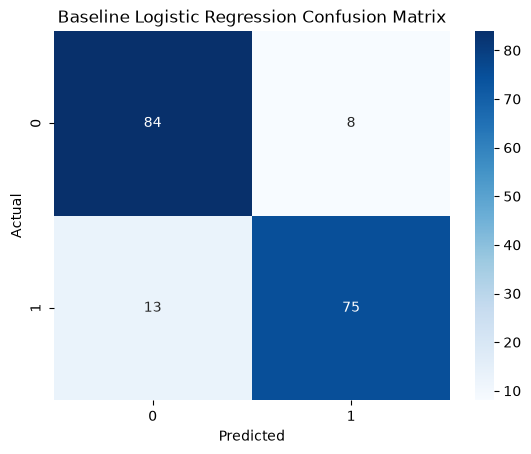

In [82]:
cm = confusion_matrix(y_test, y_pred_baseline)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Baseline Logistic Regression Confusion Matrix")

plt.show()

# 84 employees who stayed were correctly identified.
# 8 employees who stayed were incorrectly classified as leaving.
# 13 employees who left were incorrectly classified as staying.
# 75 employees who left were correctly identified.

In [83]:
print(classification_report(y_test, y_pred_baseline))

              precision    recall  f1-score   support

           0       0.87      0.91      0.89        92
           1       0.90      0.85      0.88        88

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



In [84]:
l1_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        l1_ratio=1,
        solver="liblinear",
        C=1,
        max_iter=5000
    ))
])

l1_model.fit(X_train, y_train)

y_pred_l1 = l1_model.predict(X_test)

y_pred_l1

array([0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 1])

In [85]:
print("Accuracy:", accuracy_score(y_test, y_pred_l1))

print("Precision:", precision_score(y_test, y_pred_l1))

print("Recall:", recall_score(y_test, y_pred_l1))

print("F1 Score:", f1_score(y_test, y_pred_l1))

Accuracy: 0.8722222222222222
Precision: 0.891566265060241
Recall: 0.8409090909090909
F1 Score: 0.8654970760233918


In [86]:
l2_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        l1_ratio=0,
        solver="lbfgs",
        C=1,
        max_iter=5000
    ))
])

l2_model.fit(X_train, y_train)

y_pred_l2 = l2_model.predict(X_test)

y_pred_l2

array([0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 1])

In [87]:
print("Accuracy:", accuracy_score(y_test, y_pred_l2))

print("Precision:", precision_score(y_test, y_pred_l2))

print("Recall:", recall_score(y_test, y_pred_l2))

print("F1 Score:", f1_score(y_test, y_pred_l2))

Accuracy: 0.8777777777777778
Precision: 0.8928571428571429
Recall: 0.8522727272727273
F1 Score: 0.872093023255814


In [88]:
results = {
    "Model": ["Baseline", "L1 Regularization", "L2 Regularization"],

    "Accuracy": [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred_l1),
        accuracy_score(y_test, y_pred_l2)
    ],

    "Precision": [
        precision_score(y_test, y_pred_baseline),
        precision_score(y_test, y_pred_l1),
        precision_score(y_test, y_pred_l2)
    ],

    "Recall": [
        recall_score(y_test, y_pred_baseline),
        recall_score(y_test, y_pred_l1),
        recall_score(y_test, y_pred_l2)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_baseline),
        f1_score(y_test, y_pred_l1),
        f1_score(y_test, y_pred_l2)
    ]
}

comparison_df = pd.DataFrame(results)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline,0.883333,0.903614,0.852273,0.877193
1,L1 Regularization,0.872222,0.891566,0.840909,0.865497
2,L2 Regularization,0.877778,0.892857,0.852273,0.872093


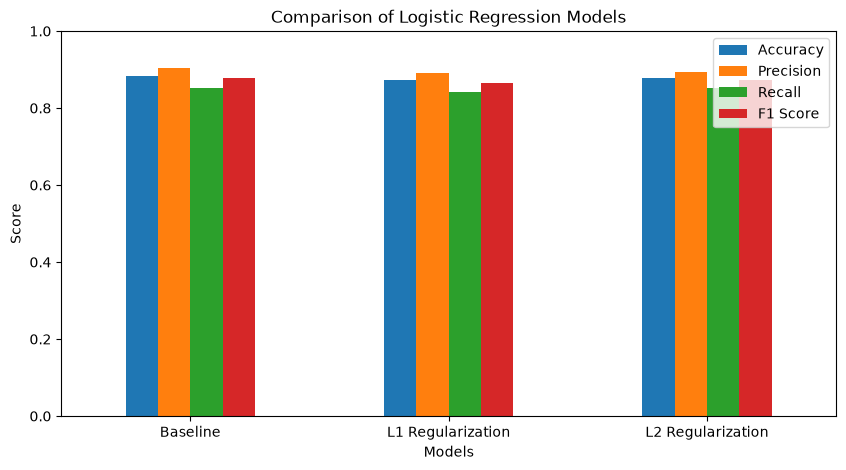

In [89]:
comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Comparison of Logistic Regression Models")
plt.ylabel("Score")
plt.xlabel("Models")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.legend()

plt.show()

In [90]:
l1_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        l1_ratio=1,
        solver="liblinear",
        max_iter=5000
    ))
])

param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

l1_grid = GridSearchCV(
    l1_pipeline,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

l1_grid.fit(X_train, y_train)

print("Best L1 Parameters:", l1_grid.best_params_)
print("Best CV F1 Score:", l1_grid.best_score_)

Best L1 Parameters: {'model__C': 1}
Best CV F1 Score: 0.856556983422655


In [91]:
l2_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        l1_ratio=0,
        solver="lbfgs",
        max_iter=5000
    ))
])

l2_grid = GridSearchCV(
    l2_pipeline,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

l2_grid.fit(X_train, y_train)

print("Best L2 Parameters:", l2_grid.best_params_)
print("Best CV F1 Score:", l2_grid.best_score_)

Best L2 Parameters: {'model__C': 1}
Best CV F1 Score: 0.8541108578597777


In [92]:
# Concept	            What you should remember

# Supervised Learning	Learning from labelled data
# Classification	    Predicting categories
# Logistic Regression	Predicting class probabilities
# Sigmoid Function	    Converts values into probabilities between 0 and 1
# Overfitting	        Model performs well on training data but poorly on unseen data
# Regularization	    Penalizes model complexity
# L1	                Absolute coefficient penalty
# L2	                Squared coefficient penalty
# StandardScaler	    Standardizes numerical features
# Train-Test Split	    Separates training and testing data
# Cross-Validation	    Evaluates model across multiple data splits
# GridSearchCV	        Searches for suitable hyperparameters
# Precision	            How reliable positive predictions are
# Recall	            How many actual positive cases are detected
# F1-score	            Harmonic mean of precision and recall
# ROC-AUC	            Measures class-discrimination ability

In [93]:
# 1. Import Libraries Covered
# 2. Load and Explore Dataset Covered
# 3. Clean Dataset Covered
# 4. Separate X and y Covered
# 5. Train-Test Split Covered
# 6. Feature Scaling Covered
# 7. Baseline Logistic Regression Covered
# 8. L1 Regularization Covered
# 9. L2 Regularization Covered
# 10. Model Evaluation and Comparison Covered
# 11. Hyperparameter Tuning Covered
# 12. Final Recommendation Covered